# Module 1 · Partie 6 : Régressions pénalisées (Ridge, Lasso, Elastic Net)

> *Multivaried Analysis 2 : Data Mining & Machine Learning*, Prof. Hélène Soyeurt, ULiège Gembloux Agro-Bio Tech, 2026-2027

**Objectifs d'apprentissage**

À la fin de ce notebook, tu sauras :

1. expliquer **pourquoi** on ajoute une pénalité à la fonction de coût des moindres carrés (surajustement, colinéarité, parcimonie) ;
2. écrire et interpréter les fonctions de coût de la **régression Ridge** (pénalité L2), de la **régression Lasso** (pénalité L1) et de l'**Elastic Net** (L1 + L2) ;
3. décrire le rôle du **paramètre de régularisation λ** et celui du **paramètre de mélange α** de `glmnet` ;
4. reproduire « à la main » les courbes de l'exemple jouet des slides (coefficients et R² en fonction de λ) ;
5. utiliser `glmnet()` et ses fonctions associées (`print`, `coef`, `predict`, `plot`, `cv.glmnet`) sur les données de lactoferrine ;
6. choisir λ en testant une grille de valeurs sur un **jeu de validation**.

**Prérequis** : parties 2 et 3 (régression univariée et multivariée, OLS, R²), partie 4 (sélection de variables) et partie 5 (fonction de coût, standardisation).

**Sommaire**

- 6.0 Préparation : packages et données
- 6.1 Pourquoi pénaliser ?
- 6.2 La régression Ridge (régularisation L2)
- 6.3 La régression Lasso (régularisation L1)
- 6.4 Ridge vs Lasso
- 6.5 La régression Elastic Net
- 6.6 Le package `glmnet` en détail
- 6.7 Application à la lactoferrine (résolution du TP)
- 6.8 Lasso sur le spectre complet
- 6.9 Choisir λ : grille sur un jeu de validation
- 6.10 Bilan : la sélection de variables
- Récapitulatif

## 6.0 Préparation : packages et données

On recharge tout ce qu'il faut pour que ce notebook soit **autonome** :

- `glmnet` : régressions pénalisées (Ridge, Lasso, Elastic Net) ;
- `knitr` : pour `kable()` (jolis tableaux).

Puis on reconstruit les objets de la résolution : `y` (teneur en lactoferrine, mg/L) et `x` (les **10 points spectraux les plus corrélés** avec `y`).

In [1]:
suppressPackageStartupMessages({
  library(glmnet)
  library(knitr)
})
options(repr.plot.width = 10, repr.plot.height = 6)   # taille des figures (spécifique à Jupyter)

# Lecture des données (le notebook tourne dans Cours/, les données sont un dossier plus haut)
lactoferrin <- read.table(file = "../lactoferrin.csv", sep = ";")
dim(lactoferrin)   # 178 lignes, 1062 colonnes : V1 = ID, V2:V1061 = spectre, V1062 = lactoferrine

[1]  178 1062

In [2]:
# Variable à expliquer
y <- as.matrix(lactoferrin[, 1062])

# Spectre de corrélation entre chaque point spectral et la lactoferrine (cf. partie 2)
correlation <- cor(lactoferrin[, 2:1061], y)[, 1]
ordercorrelation <- order(abs(correlation))      # du moins corrélé au plus corrélé

# Les 10 features les plus corrélées (+1 car la colonne 1 est l'ID de l'échantillon)
x <- as.matrix(lactoferrin[, ordercorrelation[1051:1060] + 1])
colnames(x)
dim(x)

[1] "V608" "V679" "V716" "V710" "V209" "V715" "V711" "V714" "V712" "V713"

[1] 178  10

## 6.1 Pourquoi pénaliser ?

Rappel des parties précédentes :

- quand on **ajoute des variables explicatives**, le R² de calibration augmente toujours et l'erreur diminue… mais à partir d'un moment, le modèle explique une variabilité **propre au jeu de données** et non générale : c'est le **surajustement** (*overfitting*). Le modèle se **généralise** mal à de nouvelles données ;
- quand les variables explicatives sont **fortement corrélées** (colinéarité, typique des points spectraux adjacents), l'inversion de $X'X$ devient instable : les coefficients prennent des valeurs énormes, de signes opposés, avec des erreurs standard gigantesques.

On préfère donc un modèle **parcimonieux**. Deux grandes stratégies :

1. **supprimer des variables** (sélection : corrélation, all-possible, backward, forward, stepwise, cf. partie 4) ;
2. **ajouter un paramètre de régularisation dans la fonction de coût** : c'est le principe des **régressions pénalisées**. On « force le système » à produire un modèle plus parcimonieux.

Regardons le problème sur le modèle `reg2b` de la résolution (10 features, `log10(y)`).

In [3]:
reg2b <- lm(log10(y) ~ x)
round(summary(reg2b)$coefficients, 3)

,Estimate,Std. Error,t value,Pr(>|t|)
(Intercept),1.870,0.635,2.943,0.004
xV608,-0.107,0.112,-0.960,0.339
xV679,-0.818,0.720,-1.135,0.258
xV716,-129.693,211.713,-0.613,0.541
xV710,-14.992,31.979,-0.469,0.640
xV209,13.123,24.693,0.531,0.596
xV715,430.628,561.276,0.767,0.444
xV711,102.244,128.943,0.793,0.429
xV714,-654.076,650.813,-1.005,0.316
xV712,-312.267,287.359,-1.087,0.279


**Observation** : des coefficients énormes (plusieurs centaines), de signes alternés (V714 ≈ −654, V713 ≈ +574…), et **aucun n'est significatif**, alors que chaque feature, prise seule, est significativement corrélée à `y`. C'est la signature de la **colinéarité** : la même information est partagée par plusieurs features et le modèle « compense » un grand coefficient positif par un grand coefficient négatif.

L'idée des régressions pénalisées : **interdire aux coefficients d'être trop grands** en ajoutant leur taille dans ce qu'on minimise.

> **Définition : régression pénalisée**
> On minimise non plus seulement la somme des carrés des résidus (OLS), mais
> $$\underbrace{\sum_{i=1}^n \Big(y_i - \beta_0 - \sum_{j=1}^q \beta_j x_{ij}\Big)^2}_{\text{OLS : qualité d'ajustement}} \;+\; \underbrace{\lambda \cdot P(\beta)}_{\text{pénalité : taille des coefficients}}$$
> où $P(\beta)$ mesure la « taille » du vecteur des coefficients et $\lambda \ge 0$ est le **paramètre de régularisation**.

## 6.2 La régression Ridge (régularisation L2)

### 6.2.1 Fonction de coût

La régression Ridge est une régression linéaire dont les coefficients ne sont pas seulement estimés à partir de leur capacité à bien prédire le jeu de calibration : on ajoute une **contrainte (pénalité)** à la fonction de coût, qui force les coefficients à avoir la **plus petite amplitude possible** (aussi proches de 0 que possible). Intuitivement, chaque variable prédictive aura le moins d'effet possible sur la sortie, tout en permettant une bonne prédiction.

$$\text{Coût}_{\text{Ridge}} = \sum_{i=1}^{n}\left(y_i-\beta_1x_{i1}-\dots-\beta_qx_{iq}\right)^2+\lambda\sum_{j=1}^{q}\beta_j^2$$

- le premier terme est le critère **OLS** ;
- le second est la **pénalité L2** : la somme des **carrés** des coefficients (le carré de la norme euclidienne $\|\beta\|_2^2$) ;
- **λ** est le **paramètre de régularisation** :
  - si **λ = 0** → aucune pénalité → on retrouve la **régression linéaire simple (OLS)** ;
  - si **λ ↑** → la pénalité grandit → les coefficients sont « rétrécis » (*shrinkage*) vers 0 ;
  - si λ est **trop grand** → la fonction de coût est trop pénalisée → tous les coefficients ≈ 0 → le modèle ne prédit plus rien (sous-ajustement).

> **Attention**
> - L'**intercept $\beta_0$ n'est pas pénalisé** (on ne veut pas forcer la moyenne de y vers 0). En pratique on centre X et y, on estime les pentes, puis $\beta_0 = \bar y - \sum_j \beta_j \bar x_j$.
> - Comme la pénalité porte sur la taille des coefficients, et que la taille d'un coefficient dépend de l'**unité** de la variable, il faut **toujours standardiser les variables explicatives** avant la modélisation, afin de donner la **même pénalité à toutes les variables**.

Le bon réglage de λ se fait par **essais successifs** : on teste une **grille** de valeurs de λ et on évalue chacune sur un **jeu de validation** (cf. §6.9). Le modèle Ridge aura probablement de moins bonnes performances en calibration, mais **de meilleures performances en validation** que la régression classique : Ridge permet une **meilleure généralisation**.

> **Complément : la solution analytique de Ridge**
> En dérivant le coût par rapport à β (données centrées) et en annulant la dérivée :
> $$\frac{\partial}{\partial\beta}\Big[(y-X\beta)'(y-X\beta)+\lambda\beta'\beta\Big] = -2X'(y-X\beta)+2\lambda\beta = 0 \;\Rightarrow\; \hat\beta_{\text{Ridge}} = (X'X+\lambda I)^{-1}X'y$$
> Compare avec l'OLS $\hat\beta = (X'X)^{-1}X'y$ : on ajoute simplement λ sur la diagonale de $X'X$. Pour λ > 0, la matrice $X'X+\lambda I$ est **toujours inversible**, même en cas de colinéarité parfaite ou si p > n. C'est pour cela que les slides disent : **Ridge « résout le problème de colinéarité en réduisant la valeur des coefficients b »**.

### 6.2.2 L'exemple jouet des slides

Les slides utilisent un minuscule jeu de données (4 observations, 2 variables), **standardisé par min-max** :

| y | x1 | x2 |
|---|---|---|
| 10 | 3 | 4 |
| 20 | 6 | 2 |
| 30 | 7 | 8 |
| 40 | 8 | 9 |

Rappel min-max : $x_i' = \dfrac{x_i - x_{min}}{x_{max}-x_{min}} \in [0, 1]$.

In [4]:
# Données jouet des slides
y_toy  <- c(10, 20, 30, 40)
x1_toy <- c(3, 6, 7, 8)
x2_toy <- c(4, 2, 8, 9)

# Standardisation min-max
minmax <- function(v) (v - min(v)) / (max(v) - min(v))
X_toy <- cbind(x1 = minmax(x1_toy), x2 = minmax(x2_toy))
X_toy

# Régression OLS (λ = 0) : c'est le point de départ des courbes des slides
coef(lm(y_toy ~ X_toy))

x1,x2
0.0,0.2857143
0.6,0.0000000
0.8,0.8571429
1.0,1.0000000


(Intercept)     X_toyx1     X_toyx2 
   6.857143   21.904762    9.333333

À λ = 0 on retrouve bien les valeurs de départ des graphes des slides : **b1 ≈ 21.9** et **b2 ≈ 9.3**.

On écrit maintenant une petite fonction `ridge_closed()` qui applique la formule analytique $(X'X+\lambda I)^{-1}X'y$ sur données **centrées** (intercept non pénalisé).

In [5]:
# Ridge par la formule analytique (X et y centrés -> intercept non pénalisé)
ridge_closed <- function(X, y, lambda) {
  Xc <- scale(X, center = TRUE, scale = FALSE)       # centrer chaque colonne
  yc <- y - mean(y)
  p  <- ncol(X)
  b  <- solve(crossprod(Xc) + lambda * diag(p), crossprod(Xc, yc))   # (X'X + λI)^-1 X'y
  b0 <- mean(y) - sum(colMeans(X) * b)                              # on reconstruit l'intercept
  c(b0 = b0, setNames(as.numeric(b), colnames(X)))
}

ridge_closed(X_toy, y_toy, lambda = 0)    # = OLS
ridge_closed(X_toy, y_toy, lambda = 10)   # coefficients rétrécis

b0        x1        x2 
 6.857143 21.904762  9.333333

b0        x1        x2 
23.397794  1.463972  1.351136

Calculons maintenant les coefficients et le R² pour **toute une grille de λ entre 0 et 1000**, comme sur les slides.

In [6]:
lambdas <- seq(0, 1000, by = 1)

# Une ligne par valeur de λ : intercept, b1, b2
path_ridge <- t(sapply(lambdas, function(l) ridge_closed(X_toy, y_toy, l)))

# R² = 1 - SCE_résidus / SCE_totale, calculé pour chaque λ
r2 <- function(y, yhat) 1 - sum((y - yhat)^2) / sum((y - mean(y))^2)
pred_ridge <- path_ridge[, 1] + path_ridge[, 2:3] %*% t(X_toy)   # matrice (λ × observations)
R2_ridge <- apply(pred_ridge, 1, function(yhat) r2(y_toy, yhat))

head(round(cbind(lambda = lambdas, path_ridge, R2 = R2_ridge), 3))

lambda,b0,x1,x2,R2
0,6.857,21.905,9.333,0.981
1,16.188,8.472,6.960,0.720
2,19.130,5.500,4.797,0.533
3,20.597,4.085,3.644,0.420
4,21.477,3.251,2.935,0.346
5,22.064,2.701,2.456,0.293


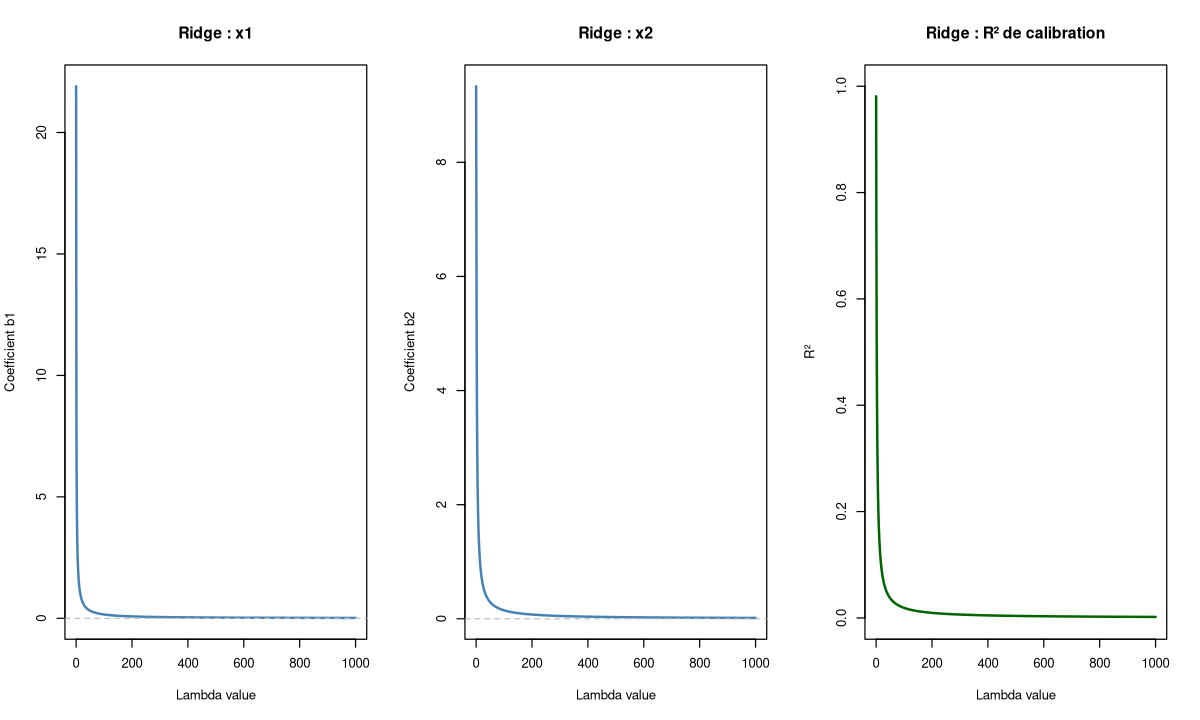

In [7]:
par(mfrow = c(1, 3))
plot(lambdas, path_ridge[, "x1"], type = "l", lwd = 2, col = "steelblue",
     xlab = "Lambda value", ylab = "Coefficient b1", main = "Ridge : x1")
abline(h = 0, lty = 2, col = "grey")
plot(lambdas, path_ridge[, "x2"], type = "l", lwd = 2, col = "steelblue",
     xlab = "Lambda value", ylab = "Coefficient b2", main = "Ridge : x2")
abline(h = 0, lty = 2, col = "grey")
plot(lambdas, R2_ridge, type = "l", lwd = 2, col = "darkgreen", ylim = c(0, 1),
     xlab = "Lambda value", ylab = "R²", main = "Ridge : R² de calibration")
par(mfrow = c(1, 1))

**Quelles conclusions ? (question des slides)**

- quand λ augmente, **b1 et b2 diminuent** et tendent **progressivement** vers 0, **sans jamais l'atteindre exactement** ;
- le plus grand coefficient (b1) est le plus fortement rétréci au début ;
- **« For sure, this impacts the prediction performances ! »** : le R² de calibration chute avec λ. C'est normal : on sacrifie un peu d'ajustement sur la calibration pour gagner en stabilité/généralisation. Tout l'art est de choisir le bon λ.

### Exercice 6.1 : Ridge à la main

Calcule les coefficients Ridge de l'exemple jouet pour **λ = 1** et **λ = 100** avec `ridge_closed()`, puis calcule le R² de calibration correspondant. Compare avec l'OLS.

In [8]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
for (l in c(0, 1, 100)) {
  b <- ridge_closed(X_toy, y_toy, l)
  yhat <- b[1] + X_toy %*% b[2:3]
  cat("lambda =", l, " b1 =", round(b[2], 3), " b2 =", round(b[3], 3),
      " R2 =", round(r2(y_toy, yhat), 3), "\n")
}
```

À λ = 0 : b1 ≈ 21.9, b2 ≈ 9.3, R² ≈ 0.98. À λ = 1 : b1 ≈ 8.5, b2 ≈ 7.0 : b1 a été beaucoup plus rétréci que b2. À λ = 100 : b1 ≈ 0.16, b2 ≈ 0.15, R² très faible. Avec seulement 4 observations, une petite valeur de λ suffit déjà à pénaliser fortement.

</details>

### Exercice 6.2 : Ridge face à une colinéarité parfaite

Ajoute à `X_toy` une 3e colonne `x3` **identique** à `x1`.

1. Ajuste une régression OLS avec `lm()` : que se passe-t-il ?
2. Ajuste une régression Ridge avec `ridge_closed()` et λ = 1. Que vaut le coefficient de x1 et de x3 ?

In [9]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
X3 <- cbind(X_toy, x3 = X_toy[, "x1"])
coef(lm(y_toy ~ X3))              # x3 = NA : "not defined because of singularities"
ridge_closed(X3, y_toy, lambda = 1)
```

1. `lm()` renvoie `NA` pour x3 : $X'X$ est **singulière** (non inversible), le modèle ne peut pas séparer l'effet de x1 et de x3.
2. Ridge fonctionne : $X'X + \lambda I$ est inversible. Les coefficients de x1 et x3 sont **égaux** : Ridge **répartit l'effet** entre les variables colinéaires au lieu d'en choisir une. C'est pour cela que Ridge permet d'**interpréter plusieurs coefficients même en présence de colinéarité**.

</details>

## 6.3 La régression Lasso (régularisation L1)

### 6.3.1 Fonction de coût

**Lasso** = *Least Absolute Shrinkage and Selection Operator*. Même principe que Ridge, mais la pénalité utilise la **valeur absolue** des coefficients au lieu de leur carré :

$$\text{Coût}_{\text{Lasso}} = \sum_{i=1}^{n}\left(y_i-\beta_1x_{i1}-\dots-\beta_qx_{iq}\right)^2+\lambda\sum_{j=1}^{q}|\beta_j|$$

C'est la **régularisation L1** ($\sum_j|\beta_j| = \|\beta\|_1$, norme L1).

Conséquences (syllabus) :

- avec la pénalité L1, des coefficients deviennent **strictement égaux à 0** → les variables correspondantes sont **complètement exclues** du modèle. Le Lasso fait donc une **sélection automatique de variables** ;
- le modèle obtenu est **plus facile à interpréter** et révèle facilement les prédicteurs les plus influents ;
- si **deux variables sont corrélées**, l'algorithme n'en choisit **qu'une**, ce qui peut conduire à une **mauvaise interprétation** (l'autre n'est pas « inutile », elle porte la même information) ;
- le risque majeur du Lasso est de **sous-ajuster** le modèle final : un bon réglage du paramètre de contrôle λ est indispensable ;
- comme pour Ridge, les **données doivent être standardisées**.

> **Complément : pourquoi des zéros exacts ? Le seuillage doux (soft-thresholding)**
> Il n'existe pas de formule fermée pour le Lasso (la valeur absolue n'est pas dérivable en 0). On l'estime par **descente de coordonnées** : on met à jour un coefficient à la fois. Pour le coefficient $j$, avec $r$ le résidu partiel (sans la variable j) et des données centrées, la mise à jour est :
> $$\beta_j \leftarrow \frac{S\!\left(\sum_i x_{ij} r_i,\ \lambda/2\right)}{\sum_i x_{ij}^2}, \qquad S(z, \gamma) = \text{signe}(z)\cdot\max(|z|-\gamma,\ 0)$$
> Si la « force » $|\sum_i x_{ij} r_i|$ d'une variable est **inférieure à λ/2**, son coefficient est mis **exactement à 0**. Avec Ridge, la mise à jour serait $\sum_i x_{ij} r_i / (\sum_i x_{ij}^2 + \lambda)$ : on divise par quelque chose de plus grand, mais on n'obtient jamais exactement 0.

In [10]:
# Seuillage doux
soft <- function(z, gamma) sign(z) * pmax(abs(z) - gamma, 0)

# Lasso par descente de coordonnées (coût du cours : SCE + λ Σ|βj|), intercept non pénalisé
lasso_cd <- function(X, y, lambda, n_iter = 500) {
  Xc <- scale(X, center = TRUE, scale = FALSE)
  yc <- y - mean(y)
  b  <- rep(0, ncol(X))
  for (it in 1:n_iter) {
    for (j in 1:ncol(X)) {
      r    <- yc - Xc[, -j, drop = FALSE] %*% b[-j]          # résidu partiel sans la variable j
      b[j] <- soft(sum(Xc[, j] * r), lambda / 2) / sum(Xc[, j]^2)
    }
  }
  b0 <- mean(y) - sum(colMeans(X) * b)
  c(b0 = b0, setNames(b, colnames(X)))
}

lasso_cd(X_toy, y_toy, lambda = 0)    # = OLS
lasso_cd(X_toy, y_toy, lambda = 20)   # b2 presque nul
lasso_cd(X_toy, y_toy, lambda = 50)   # tout est à 0 (sauf l'intercept)

b0        x1        x2 
 6.857143 21.904762  9.333333

b0        x1        x2 
18.371429  9.380952  1.866667

b0 x1 x2 
25  0  0

x1_nul_a_partir_de x2_nul_a_partir_de 
                32                 25

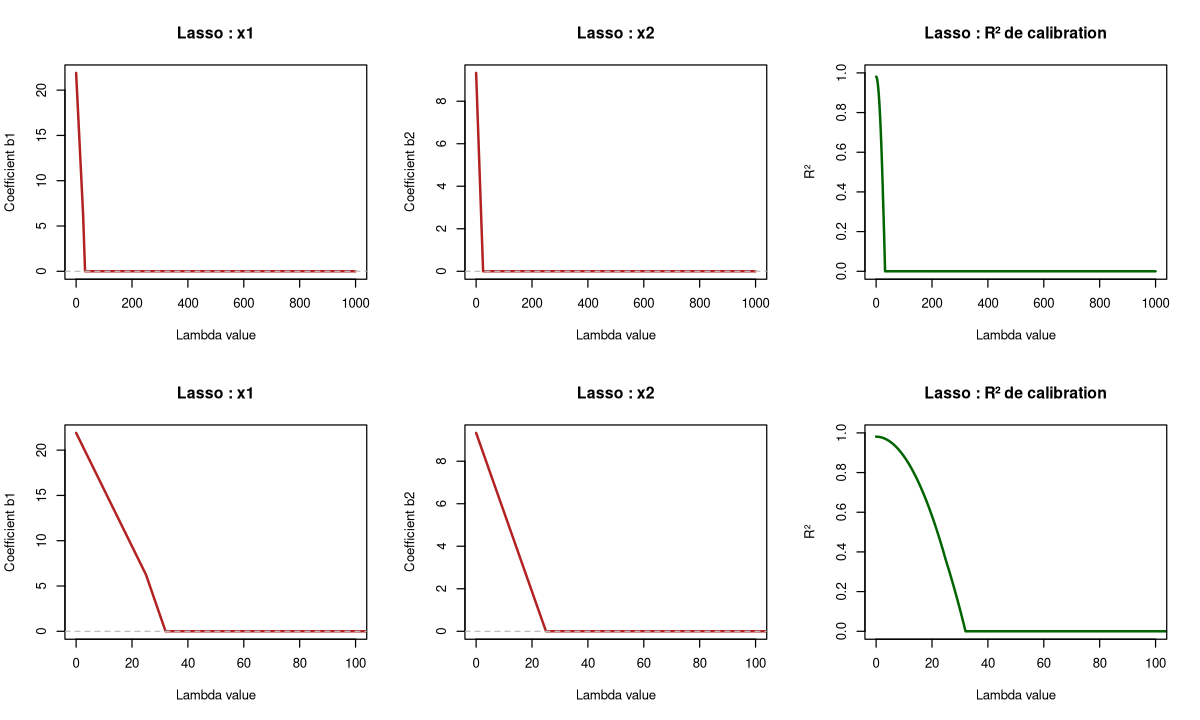

In [11]:
lambdas_l   <- seq(0, 1000, by = 1)
path_lasso  <- t(sapply(lambdas_l, function(l) lasso_cd(X_toy, y_toy, l, n_iter = 200)))
pred_lasso  <- path_lasso[, 1] + path_lasso[, 2:3] %*% t(X_toy)
R2_lasso    <- apply(pred_lasso, 1, function(yhat) r2(y_toy, yhat))

par(mfrow = c(2, 3))
# Ligne 1 : échelle des slides (0 à 1000) ; ligne 2 : zoom sur 0-100 pour bien voir les zéros
for (zoom in c(1000, 100)) {
  plot(lambdas_l, path_lasso[, "x1"], type = "l", lwd = 2, col = "firebrick", xlim = c(0, zoom),
       xlab = "Lambda value", ylab = "Coefficient b1", main = "Lasso : x1")
  abline(h = 0, lty = 2, col = "grey")
  plot(lambdas_l, path_lasso[, "x2"], type = "l", lwd = 2, col = "firebrick", xlim = c(0, zoom),
       xlab = "Lambda value", ylab = "Coefficient b2", main = "Lasso : x2")
  abline(h = 0, lty = 2, col = "grey")
  plot(lambdas_l, R2_lasso, type = "l", lwd = 2, col = "darkgreen", ylim = c(0, 1), xlim = c(0, zoom),
       xlab = "Lambda value", ylab = "R²", main = "Lasso : R² de calibration")
}
par(mfrow = c(1, 1))

# À partir de quel λ chaque coefficient devient-il exactement nul ?
c(x1_nul_a_partir_de = lambdas_l[min(which(path_lasso[, "x1"] == 0))],
  x2_nul_a_partir_de = lambdas_l[min(which(path_lasso[, "x2"] == 0))])

**Quelles conclusions ? (question des slides)**

- avec le Lasso, les coefficients atteignent **exactement 0**, et **très vite** (ici dès λ = 25 pour b2 et λ = 32 pour b1, alors qu'avec Ridge ils sont encore non nuls à λ = 1000) ;
- b2 (le plus petit effet) est éliminé **avant** b1 : le Lasso garde les variables à effet fort ;
- au-delà, R² = 0 : le modèle se réduit à l'intercept (la moyenne de y), c'est le **sous-ajustement** extrême.

> Sur les graphes des slides, la courbe de b2 du Lasso descend légèrement sous 0 avant de s'annuler, et l'échelle de λ peut différer : le résultat exact dépend de l'**implémentation** (algorithme, normalisation de la fonction de coût, voir §6.6.3). Le message reste le même : **Lasso → zéros exacts, Ridge → rétrécissement progressif**.

### Exercice 6.3 : seuillage doux

1. Calcule `soft(z, 1)` pour `z = c(-3, -0.5, 0, 0.8, 2.5)`. Que remarques-tu ?
2. Trace la fonction `soft(z, 1)` pour `z` entre −3 et 3, et superpose la droite `z / 2` (le « rétrécissement » de type Ridge pour comparer).

In [12]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
soft(c(-3, -0.5, 0, 0.8, 2.5), 1)     # -2  0  0  0  1.5
z <- seq(-3, 3, by = 0.01)
plot(z, soft(z, 1), type = "l", lwd = 2, col = "firebrick", ylab = "valeur rétrécie",
     main = "Seuillage doux (Lasso) vs rétrécissement proportionnel (Ridge)")
lines(z, z / 2, lwd = 2, col = "steelblue", lty = 2)
abline(h = 0, v = 0, col = "grey")
legend("topleft", c("Lasso : S(z, 1)", "Ridge : z / 2"), col = c("firebrick", "steelblue"),
       lty = c(1, 2), lwd = 2)
```

Toutes les valeurs |z| ≤ 1 sont **mises à 0** ; les autres sont « rapprochées » de 0 de 1 unité. Le Lasso crée une **zone morte** autour de 0, d'où les coefficients exactement nuls. Ridge divise (rétrécit proportionnellement) : il ne produit jamais un 0 exact.

</details>

### Exercice 6.4 : Lasso et variables corrélées

Reprends la matrice avec `x3` identique à `x1` (exercice 6.2) et applique `lasso_cd()` avec λ = 5. Combien de variables parmi x1 et x3 le Lasso garde-t-il ? Quel risque d'interprétation cela pose-t-il ?

In [13]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
X3 <- cbind(X_toy, x3 = X_toy[, "x1"])
lasso_cd(X3, y_toy, lambda = 5)
```

Le Lasso attribue tout l'effet à **une seule** des deux variables identiques (ici x1, mise à jour en premier) et met l'autre à 0 (tu peux obtenir une valeur du type `9.5e-15` : c'est un **zéro numérique**, dû aux arrondis en virgule flottante). Si on interprétait naïvement le modèle, on conclurait que x3 n'a « aucun effet » alors qu'elle porte exactement la même information que x1. C'est la mise en garde du syllabus : **si 2 variables sont corrélées, le Lasso n'en choisit qu'une, ce qui peut mener à une mauvaise interprétation**. Ridge, lui, partage l'effet (exercice 6.2).

</details>

## 6.4 Ridge vs Lasso

### 6.4.1 Les chemins de coefficients (graphes `glmnet`)

Dans les slides, les comparaisons sont faites avec les graphes du package `glmnet` : coefficients en fonction de **log(λ)** (*Log Lambda*) ou de la **norme** du vecteur de coefficients (*L1 Norm*). Le chiffre en haut de chaque graphe est le **nombre de coefficients non nuls** pour cette valeur de λ.

> **Version de glmnet** : depuis glmnet 5, `plot(mod, xvar = "lambda")` trace par défaut **−log(λ)** (λ décroît vers la droite), ce qui retourne les graphes horizontalement par rapport aux slides. On ajoute donc **`sign.lambda = 1`** pour retrouver l'axe *Log Lambda* des slides (λ croît vers la droite, les coefficients s'écrasent vers 0 à droite).

On les reproduit sur l'exemple jouet (le fonctionnement détaillé de `glmnet` est expliqué au §6.6).

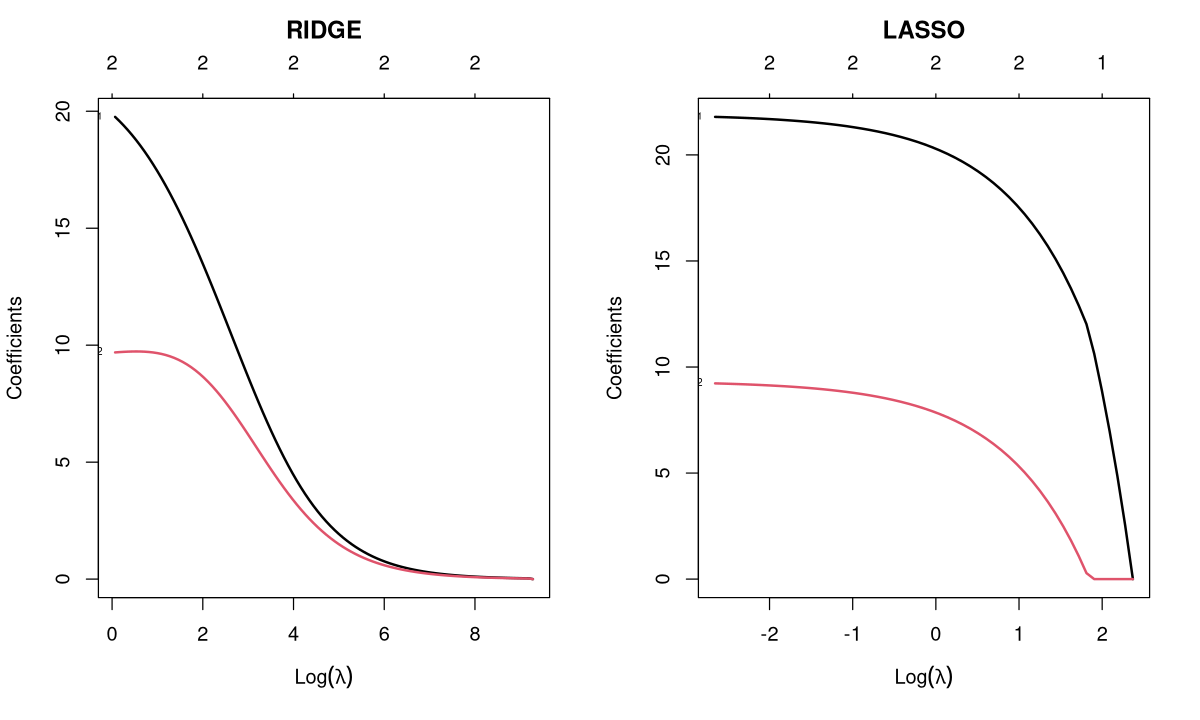

In [14]:
ridge_toy <- glmnet(X_toy, y_toy, alpha = 0)   # alpha = 0 -> Ridge
lasso_toy <- glmnet(X_toy, y_toy, alpha = 1)   # alpha = 1 -> Lasso

par(mfrow = c(1, 2))
plot(ridge_toy, xvar = "lambda", sign.lambda = 1, label = TRUE, lwd = 2); title("RIDGE", line = 2.5)
plot(lasso_toy, xvar = "lambda", sign.lambda = 1, label = TRUE, lwd = 2); title("LASSO", line = 2.5)
par(mfrow = c(1, 1))

Lecture des graphes :

- **RIDGE** : en haut, toujours « 2 2 2 2 … » → les deux coefficients restent **non nuls** ; ils décroissent doucement vers 0 quand log(λ) augmente ;
- **LASSO** : en haut, « 2 2 … 1 … 0 0 » → les coefficients **tombent à 0** l'un après l'autre, et brutalement.

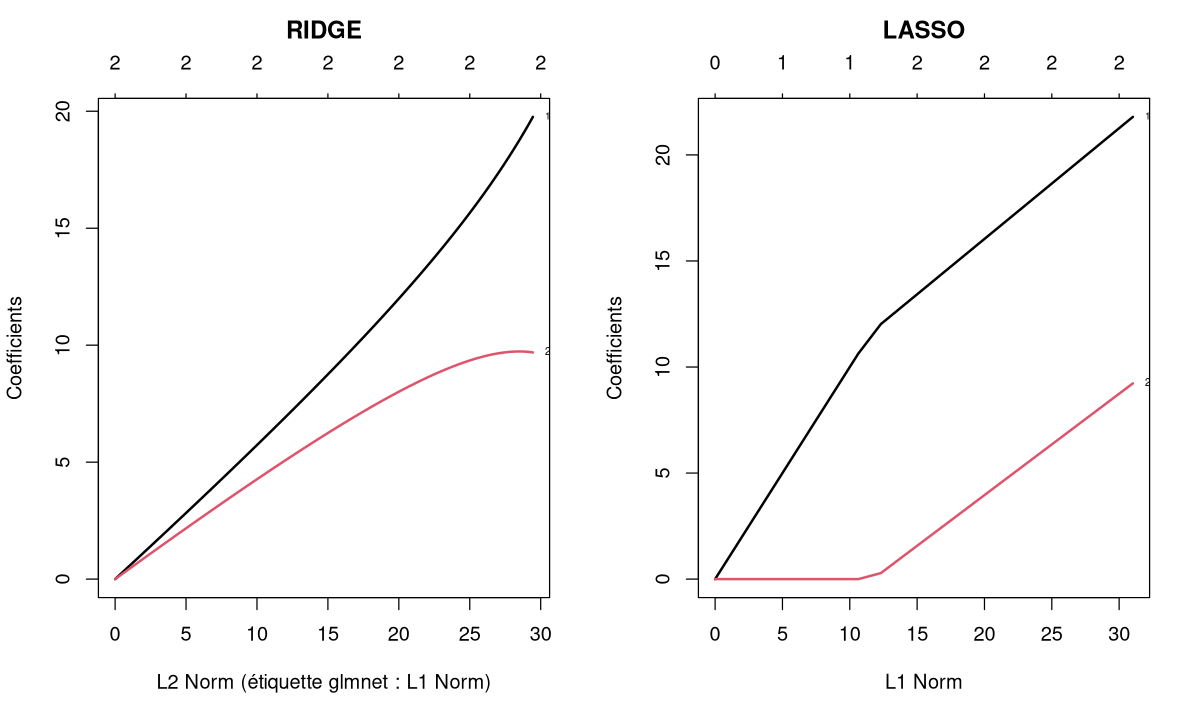

In [15]:
par(mfrow = c(1, 2))
plot(ridge_toy, xvar = "norm", label = TRUE, lwd = 2, xlab = "L2 Norm (étiquette glmnet : L1 Norm)"); title("RIDGE", line = 2.5)
plot(lasso_toy, xvar = "norm", label = TRUE, lwd = 2); title("LASSO", line = 2.5)
par(mfrow = c(1, 1))

Avec `xvar = "norm"`, l'axe des x est la norme des coefficients : à gauche (norme 0) tout est nul (λ très grand), à droite on retrouve l'OLS (λ = 0). `glmnet` écrit toujours « L1 Norm » sur l'axe, ce qui est **faux pour Ridge** (c'est la norme L2 qui est pénalisée) : c'est la remarque de la résolution (« *The x name for the x graph is wrong. It is the L2 norm* »). On corrige donc l'étiquette avec `xlab`.

### 6.4.2 Conclusions des slides : Ridge vs Lasso

- les coefficients **atteignent 0 plus lentement avec Ridge** (en fait, jamais exactement) ;
  - le **Lasso est un outil de sélection de variables** ;
  - **Ridge** est intéressant pour **interpréter plusieurs coefficients même si de la colinéarité existe**, grâce au paramètre λ ;
- si l'on attend **beaucoup de petits effets** → **Ridge** ;
- si l'on attend **quelques variables à effets modérés ou forts** → **Lasso** ;
- **toujours standardiser les variables explicatives avant la modélisation.**

> **Complément : interprétation géométrique**
> Minimiser « OLS + λ·pénalité » revient à minimiser l'OLS **sous une contrainte de budget** : $\sum\beta_j^2 \le t$ (Ridge) ou $\sum|\beta_j| \le t$ (Lasso). En 2D, la zone permise est un **disque** pour Ridge et un **losange** pour Lasso. La solution est le premier point où les ellipses de niveau de la SCE touchent cette zone. Le losange a des **coins sur les axes** ($\beta_1 = 0$ ou $\beta_2 = 0$) : les ellipses les touchent souvent en premier → zéros exacts. Le disque n'a pas de coins → les deux coefficients restent non nuls.

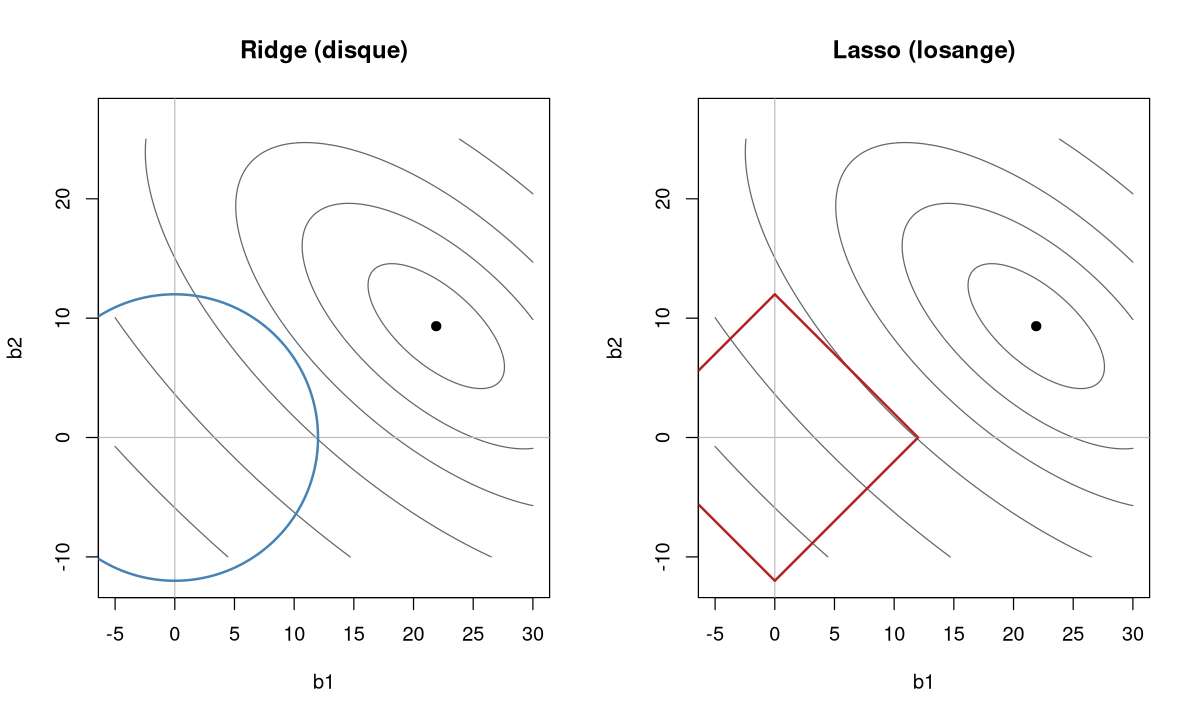

In [16]:
# Illustration géométrique (complément) : ellipses de niveau de la SCE de l'exemple jouet
Xc <- scale(X_toy, scale = FALSE); yc <- y_toy - mean(y_toy)
b1g <- seq(-5, 30, length.out = 200); b2g <- seq(-10, 25, length.out = 200)
SCE <- outer(b1g, b2g, Vectorize(function(a, b) sum((yc - Xc %*% c(a, b))^2)))

t_budget <- 12
par(mfrow = c(1, 2))
for (type in c("Ridge (disque)", "Lasso (losange)")) {
  contour(b1g, b2g, SCE, levels = c(5, 20, 50, 100, 200, 400, 700), drawlabels = FALSE,
          col = "grey40", xlab = "b1", ylab = "b2", main = type, asp = 1)
  abline(h = 0, v = 0, col = "grey")
  points(21.9, 9.33, pch = 19, col = "black")              # solution OLS
  if (type == "Ridge (disque)") {
    th <- seq(0, 2 * pi, length.out = 200)
    polygon(t_budget * cos(th), t_budget * sin(th), border = "steelblue", lwd = 2)
  } else {
    polygon(c(t_budget, 0, -t_budget, 0), c(0, t_budget, 0, -t_budget), border = "firebrick", lwd = 2)
  }
}
par(mfrow = c(1, 1))

Le point noir est la solution OLS. Les ellipses grises sont les courbes de même SCE. En agrandissant progressivement les ellipses jusqu'à toucher la zone colorée, on trouve la solution pénalisée : pour le losange, le contact se fait souvent sur un **coin** (un coefficient nul).

### Question de compréhension 6.5

Vrai ou faux ?

1. Avec λ = 0, Ridge, Lasso et OLS donnent les mêmes coefficients.
2. Ridge peut servir à sélectionner des variables, car ses coefficients deviennent exactement nuls pour λ assez grand.
3. Il est inutile de standardiser les variables avant un Lasso si elles sont toutes dans la même unité.
4. Si on s'attend à ce que les 1060 points d'un spectre contribuent tous un peu, Ridge est un choix naturel.

<details>
<summary><b>Voir la solution</b></summary>

1. **Vrai** : sans pénalité, on minimise uniquement l'OLS.
2. **Faux** : Ridge rétrécit les coefficients vers 0 sans jamais les annuler exactement ; c'est le Lasso qui sélectionne.
3. **Faux** (en général) : même unité ne veut pas dire même variance. Une variable de faible variance a besoin d'un grand coefficient pour avoir le même effet, elle serait donc plus pénalisée. Le cours dit : *« Take care to standardize always the explaining variables before the modeling »*. (Dans `glmnet`, c'est fait par défaut avec `standardize = TRUE`.)
4. **Vrai** : « beaucoup de petits effets → Ridge ».

</details>

## 6.5 La régression Elastic Net

Le choix entre Ridge et Lasso peut être complexe. Une **combinaison des deux propriétés** peut être intéressante : c'est le but de l'**Elastic Net**, qui inclut **les deux pénalités L1 et L2**.

Forme du syllabus (deux paramètres de régularisation) :

$$\text{Coût}_{\text{ElasticNet}} = \sum_{i=1}^{n}\left(y_i-\beta_1x_{i1}-\dots-\beta_qx_{iq}\right)^2+\lambda_2\sum_{j=1}^{q}\beta_j^2+\lambda_1\sum_{j=1}^{q}|\beta_j|$$

Forme utilisée par le package **GLMNET** (slide « ElasticNet – GLMNET package ») :

$$\min_{\beta_0,\beta}\ \underbrace{\frac{1}{N}\sum_{i=1}^{N} w_i\, l\!\left(y_i,\ \beta_0+\beta^T x_i\right)}_{\text{OLS (perte)}} \;+\; \underbrace{\lambda\left[\frac{(1-\alpha)}{2}\|\beta\|_2^2+\alpha\|\beta\|_1\right]}_{\text{pénalité}}$$

- $l(y_i, \cdot)$ est la **fonction de perte** ; pour une variable y quantitative (`family = "gaussian"`), $l = \frac{1}{2}(y_i - \beta_0 - \beta^Tx_i)^2$ → on retrouve les moindres carrés ;
- $w_i$ sont des poids d'observation (1 par défaut) ;
- **λ** règle la force **totale** de la pénalité ;
- **α ∈ [0, 1]** règle le **mélange** :
  - **α = 0** → pénalité purement L2 → **Ridge** ;
  - **α = 1** → pénalité purement L1 → **Lasso** ;
  - **α = 0.5** → « au milieu » : 50 % L1, 50 % L2.

Correspondance avec le syllabus (à un facteur de normalisation près) : $\lambda_1 \leftrightarrow \lambda\alpha$ et $\lambda_2 \leftrightarrow \lambda(1-\alpha)/2$.

> **Complément : pourquoi l'Elastic Net ?** La partie L1 garde la capacité de **sélection** du Lasso ; la partie L2 rend le modèle **stable face aux variables corrélées** : au lieu de n'en choisir qu'une au hasard, l'Elastic Net tend à **garder ensemble** des groupes de variables corrélées (effet de groupe), très utile pour des points spectraux adjacents.

In [17]:
# Elastic Net sur l'exemple jouet avec x3 = copie de x1
X3 <- cbind(X_toy, x3 = X_toy[, "x1"])
cbind(Lasso      = as.numeric(coef(glmnet(X3, y_toy, alpha = 1,   lambda = 1))),
      ElasticNet = as.numeric(coef(glmnet(X3, y_toy, alpha = 0.5, lambda = 1))),
      Ridge      = as.numeric(coef(glmnet(X3, y_toy, alpha = 0,   lambda = 1))))

Lasso,ElasticNet,Ridge
8.618451,8.032402,7.467797
20.291413,10.464851,10.659936
7.852508,8.425106,8.934694
0.000000,10.292063,10.582997


Sur la copie parfaite x1 = x3 : le **Lasso** garde une seule des deux (coefficient 0 pour l'autre), alors que l'**Elastic Net** et **Ridge** **partagent** l'effet entre x1 et x3 (lignes 2 et 4).

### Exercice 6.6 : l'effet de α

Sur l'exemple jouet (`X_toy`, `y_toy`), trace côte à côte les chemins de coefficients (`xvar = "lambda", sign.lambda = 1`) pour α = 0, 0.5 et 1. Décris l'évolution.

In [18]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
par(mfrow = c(1, 3))
for (a in c(0, 0.5, 1)) {
  m <- glmnet(X_toy, y_toy, alpha = a)
  plot(m, xvar = "lambda", sign.lambda = 1, label = TRUE, lwd = 2)
  title(paste("alpha =", a), line = 2.5)
}
par(mfrow = c(1, 1))
```

Quand α passe de 0 à 1, les coefficients atteignent 0 de plus en plus **brutalement** et pour des λ de plus en plus **petits** : on passe d'un comportement Ridge (rétrécissement doux, jamais nul) à un comportement Lasso (sélection). α = 0.5 est intermédiaire : les coefficients finissent par s'annuler (part L1), mais plus progressivement.

</details>

## 6.6 Le package `glmnet` en détail

### 6.6.1 La fonction `glmnet()`

> **Fonction R** : `glmnet(x, y, family = "gaussian", alpha = 1, nlambda = 100, lambda = NULL, standardize = TRUE, intercept = TRUE, ...)`
> Ajuste un modèle linéaire (généralisé) pénalisé **pour toute une séquence de λ** à la fois (le « chemin de régularisation »).

| Argument | Rôle |
|---|---|
| `x` | **matrice** des variables explicatives (n × p). Pas de formule, pas de data.frame : utilise `as.matrix()` |
| `y` | variable à expliquer (vecteur ou matrice 1 colonne) |
| `family` | type de y : `"gaussian"` pour une y **quantitative** (régression linéaire) ; `"binomial"`, `"multinomial"`, `"poisson"`… pour d'autres cas (module 3 : régression logistique) |
| `alpha` | mélange : **0 = Ridge**, **1 = Lasso** (défaut), entre les deux = Elastic Net |
| `lambda` | séquence de λ choisie par l'utilisateur, **décroissante** de préférence. Si `NULL` (recommandé), glmnet calcule lui-même une séquence de `nlambda` valeurs adaptée aux données |
| `nlambda` | nombre de valeurs de λ générées automatiquement (100 par défaut) |
| `standardize` | `TRUE` (défaut) : glmnet **standardise lui-même** les x avant l'ajustement puis renvoie les coefficients **à l'échelle d'origine** |
| `intercept` | ajuster un intercept (non pénalisé) ou non |

**Ce que contient l'objet renvoyé** (classe `"elnet"`, `"glmnet"`) :

| Élément | Contenu |
|---|---|
| `mod$lambda` | la séquence de λ utilisée |
| `mod$a0` | les intercepts (un par λ) |
| `mod$beta` | matrice (creuse) des coefficients : une ligne par variable, une colonne par λ |
| `mod$df` | nombre de coefficients non nuls pour chaque λ |
| `mod$dev.ratio` | fraction de la déviance expliquée (= R² de calibration en gaussien) pour chaque λ |

> **Points d'attention** : c'est **toujours un chemin**. Toutes les fonctions qui suivent (`coef`, `predict`) demandent donc de préciser **pour quel λ** via l'argument `s` (pour *s*hrinkage).

### 6.6.2 Les fonctions associées

| Fonction | Usage |
|---|---|
| `print(mod)` | tableau `Df` (nb de coefficients ≠ 0), `%Dev` (% de déviance expliquée ≈ R² × 100), `Lambda` |
| `coef(mod, s = 0.01)` | coefficients (intercept compris) pour λ = 0.01 ; sans `s` → tous les λ |
| `predict(mod, newx = Xnew, s = 0.01)` | prédictions pour de nouvelles observations (`newx` = matrice avec les mêmes colonnes que x) |
| `predict(mod, s = 0.01, type = "coefficients")` | équivalent à `coef()` |
| `plot(mod, xvar = "norm")` | coefficients vs norme du vecteur de coefficients (défaut) |
| `plot(mod, xvar = "lambda", sign.lambda = 1)` | coefficients vs log(λ) (sans `sign.lambda = 1`, glmnet ≥ 5 trace −log(λ)) |
| `plot(mod, xvar = "dev")` | coefficients vs fraction de déviance expliquée |
| `plot(..., label = TRUE)` | numérote les courbes (numéro de colonne de x) |
| `cv.glmnet(x, y, alpha, nfolds = 10)` | choisit λ par **validation croisée** (§6.9) |

In [19]:
# Démonstration sur l'exemple jouet
lasso_toy <- glmnet(X_toy, y_toy, alpha = 1)
print(lasso_toy)       # Df / %Dev / Lambda


Call:  glmnet(x = X_toy, y = y_toy, alpha = 1) 

   Df  %Dev  Lambda
1   0  0.00 10.6900
2   1 15.52  9.7410
3   1 28.41  8.8750
4   1 39.11  8.0870
5   1 47.99  7.3690
6   1 55.37  6.7140
7   2 61.89  6.1170
8   2 68.04  5.5740
9   2 73.14  5.0790
10  2 77.38  4.6280
11  2 80.90  4.2170
12  2 83.82  3.8420
13  2 86.24  3.5010
14  2 88.25  3.1900
15  2 89.92  2.9060
16  2 91.31  2.6480
17  2 92.46  2.4130
18  2 93.42  2.1990
19  2 94.21  2.0030
20  2 94.87  1.8250
21  2 95.42  1.6630
22  2 95.87  1.5150
23  2 96.25  1.3810
24  2 96.56  1.2580
25  2 96.82  1.1460
26  2 97.04  1.0440
27  2 97.22  0.9517
28  2 97.37  0.8671
29  2 97.49  0.7901
30  2 97.59  0.7199
31  2 97.68  0.6560
32  2 97.75  0.5977
33  2 97.81  0.5446
34  2 97.86  0.4962
35  2 97.90  0.4521
36  2 97.93  0.4120
37  2 97.96  0.3754
38  2 97.98  0.3420
39  2 98.00  0.3116
40  2 98.02  0.2839
41  2 98.03  0.2587
42  2 98.04  0.2357
43  2 98.05  0.2148
44  2 98.06  0.1957
45  2 98.06  0.1783
46  2 98.07  0.1625
47  2 98.0

In [20]:
length(lasso_toy$lambda)          # nb de λ effectivement utilisés
head(lasso_toy$df, 15)            # nb de coefficients non nuls
coef(lasso_toy, s = 1)            # coefficients pour λ = 1
predict(lasso_toy, newx = X_toy, s = 1)   # prédictions des 4 observations pour λ = 1

[1] 55

[1] 0 1 1 1 1 1 2 2 2 2 2 2 2 2 2

3 x 1 sparse Matrix of class "dgCMatrix"
                  s=1
(Intercept)  8.618785
x1          20.290219
x2           7.853223

s=1
10.86256
20.79292
31.58229
36.76223


Remarque : glmnet s'est arrêté avant les 100 valeurs de λ : il stoppe quand la fraction de déviance expliquée n'évolue plus (on est revenu au modèle OLS).

### 6.6.3 L'échelle de λ dépend de l'implémentation

Le λ de glmnet **n'est pas le même nombre** que le λ de la formule du cours, car la fonction de coût n'est pas normalisée de la même façon :

| | Cours (syllabus/slides) | glmnet |
|---|---|---|
| terme OLS | $\sum_i e_i^2$ (SCE) | $\frac{1}{2n}\sum_i e_i^2$ (SCE divisée par **2n**) |
| pénalité Ridge | $\lambda\sum\beta_j^2$ | $\lambda\cdot\frac{1}{2}\sum\beta_j^2$ |
| pénalité Lasso | $\lambda\sum|\beta_j|$ | $\lambda\sum|\beta_j|$ |

En multipliant le coût glmnet par 2n, on trouve les correspondances :

- **Lasso** : $\lambda_{\text{glmnet}} = \lambda_{\text{cours}} / (2n)$ ;
- **Ridge** : $\lambda_{\text{glmnet}} = \lambda_{\text{cours}} / n$… **mais** pour `family = "gaussian"`, glmnet **standardise aussi y** en interne (division par son écart-type $s_y$ calculé en 1/n), ce qui donne en pratique $\lambda_{\text{glmnet}} = \lambda_{\text{cours}}\cdot s_y / n$.

Vérifions-le numériquement (avec `standardize = FALSE` pour travailler sur les mêmes x min-max que nos fonctions maison).

In [21]:
n_toy <- length(y_toy)
s_y   <- sqrt(mean((y_toy - mean(y_toy))^2))   # écart-type de y en 1/n

lambda_cours <- 10
rbind(
  Lasso_maison  = lasso_cd(X_toy, y_toy, lambda_cours)[2:3],
  Lasso_glmnet  = as.numeric(coef(glmnet(X_toy, y_toy, alpha = 1, standardize = FALSE,
                                         lambda = lambda_cours / (2 * n_toy))))[2:3],
  Ridge_maison  = ridge_closed(X_toy, y_toy, lambda_cours)[2:3],
  Ridge_glmnet  = as.numeric(coef(glmnet(X_toy, y_toy, alpha = 0, standardize = FALSE,
                                         lambda = lambda_cours * s_y / n_toy)))[2:3]
)

,x1,x2
Lasso_maison,15.642857,5.600000
Lasso_glmnet,15.644764,5.598859
Ridge_maison,1.463972,1.351136
Ridge_glmnet,1.463972,1.351136


Les coefficients coïncident. **À retenir** : ne compare jamais des valeurs de λ entre deux logiciels (ou entre le cours et glmnet) sans vérifier la définition de la fonction de coût. Ce qui compte, c'est la **forme du chemin** et le λ **choisi par validation** au sein d'un même outil.

### Exercice 6.7 : manipuler un objet glmnet

Avec `ridge_toy <- glmnet(X_toy, y_toy, alpha = 0)` :

1. combien de valeurs de λ ont été utilisées ? Quelle est la plus grande et la plus petite ?
2. affiche les coefficients pour λ = 0.5 et λ = 50 ;
3. prédis y pour une nouvelle observation dont les valeurs min-max sont x1 = 0.5 et x2 = 0.5, pour λ = 0.5.

In [22]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
ridge_toy <- glmnet(X_toy, y_toy, alpha = 0)
length(ridge_toy$lambda); range(ridge_toy$lambda)
coef(ridge_toy, s = c(0.5, 50))
new_obs <- matrix(c(0.5, 0.5), nrow = 1, dimnames = list(NULL, c("x1", "x2")))
predict(ridge_toy, newx = new_obs, s = 0.5)
```

`newx` doit être une **matrice** avec le même nombre de colonnes (dans le même ordre) que la matrice x utilisée pour l'ajustement. `s` peut être un vecteur : on obtient alors une colonne par λ demandé. Si `s` ne fait pas partie de la séquence, glmnet **interpole** linéairement entre les λ voisins (ajoute `exact = TRUE, x = ..., y = ...` pour un recalcul exact).

</details>

## 6.7 Application à la lactoferrine (résolution du TP)

On reprend exactement les commandes de la résolution, sur les **10 features les plus corrélées** (`x`) et **`log10(y)`** (la transformation qui rendait les résidus normaux). La séquence de λ choisie dans la résolution est `c(1000, 100, 10, 1, 0.05, 0.01)`.

### 6.7.1 Ridge

In [23]:
# family = "gaussian" car y est quantitative ; alpha = 0 -> Ridge
ridge.mod <- glmnet(x, log10(y), standardize = TRUE, alpha = 0,
                    lambda = c(1000, 100, 10, 1, 0.05, 0.01), family = "gaussian")
print(ridge.mod)


Call:  glmnet(x = x, y = log10(y), family = "gaussian", alpha = 0, lambda = c(1000,      100, 10, 1, 0.05, 0.01), standardize = TRUE) 

  Df  %Dev Lambda
1 10  0.15  1e+03
2 10  1.45  1e+02
3 10 10.31  1e+01
4 10 26.69  1e+00
5 10 37.28  5e-02
6 10 38.28  1e-02


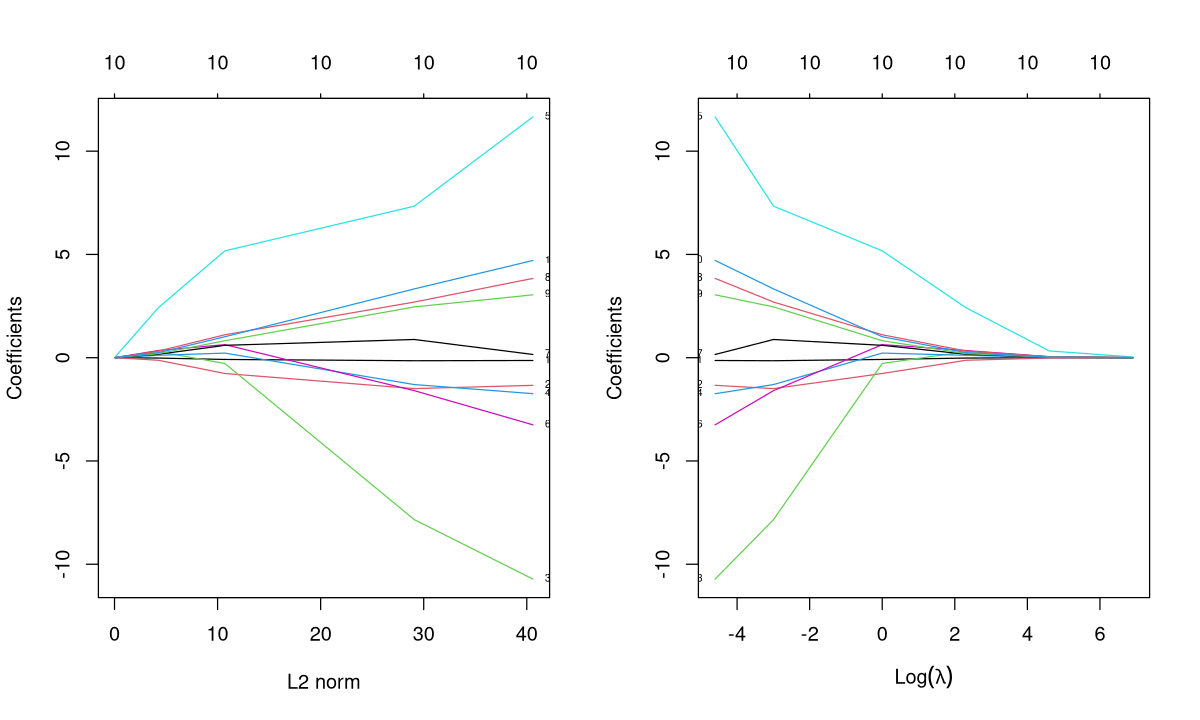

In [24]:
par(mfrow = c(1, 2))   # 2 graphes sur une ligne
plot(ridge.mod, "norm", xlab = "L2 norm", label = TRUE)
plot(ridge.mod, "lambda", sign.lambda = 1, label = TRUE)
par(mfrow = c(1, 1))

Commentaires de la résolution :

- le nom de l'axe x du graphe de gauche est faux par défaut : c'est la **norme L2** (d'où le `xlab = "L2 norm"`) ;
- quand **log λ augmente**, les coefficients **tendent vers 0** : c'est attendu, on augmente l'importance de la pénalité ;
- si la pénalité est trop forte, tous les coefficients valent 0 ; **Ridge tend à donner une faible valeur à tous les coefficients** (`Df` reste égal à 10 : aucun coefficient n'est exactement nul) ;
- `%Dev` (≈ R² × 100) passe de 0.15 % (λ = 1000) à 38 % (λ = 0.01), à comparer au R² = 0.40 de l'OLS `reg2b`.

Comparons les coefficients Ridge (λ = 0.01) avec ceux de l'OLS :

In [25]:
round(cbind(OLS = coef(reg2b), Ridge_0.01 = as.numeric(coef(ridge.mod, s = 0.01))), 2)

,OLS,Ridge_0.01
(Intercept),1.87,2.15
xV608,-0.11,-0.14
xV679,-0.82,-1.34
xV716,-129.69,-10.72
xV710,-14.99,-1.74
xV209,13.12,11.66
xV715,430.63,-3.25
xV711,102.24,0.16
xV714,-654.08,3.84
xV712,-312.27,3.04


Les coefficients Ridge sont **beaucoup plus petits et plus stables** que les coefficients OLS gonflés par la colinéarité, pour une perte de R² très faible.

### 6.7.2 Lasso

In [26]:
# alpha = 1 -> Lasso
lasso.mod <- glmnet(x, log10(y), alpha = 1,
                    lambda = c(1000, 100, 10, 1, 0.05, 0.01), family = "gaussian")
print(lasso.mod)
coef(lasso.mod)


Call:  glmnet(x = x, y = log10(y), family = "gaussian", alpha = 1, lambda = c(1000,      100, 10, 1, 0.05, 0.01)) 

  Df  %Dev Lambda
1  0  0.00  1e+03
2  0  0.00  1e+02
3  0  0.00  1e+01
4  0  0.00  1e+00
5  4 30.92  5e-02
6  5 37.55  1e-02


11 x 6 sparse Matrix of class "dgCMatrix"
                  s0       s1       s2       s3         s4         s5
(Intercept) 2.020004 2.020004 2.020004 2.020004  2.6339315  2.0648689
V608        .        .        .        .        -0.0388308 -0.1242720
V679        .        .        .        .        -1.1184607 -1.4188299
V716        .        .        .        .         .         -9.4526938
V710        .        .        .        .         .         -0.5288529
V209        .        .        .        .         .          .        
V715        .        .        .        .         .          .        
V711        .        .        .        .         .          .        
V714        .        .        .        .         .          .        
V712        .        .        .        .         3.5039914  .        
V713        .        .        .        .         0.5101202  8.5956926

Warning message in regularize.values(x, y, ties, missing(ties), na.rm = na.rm):
“collapsing to unique 'x' values”


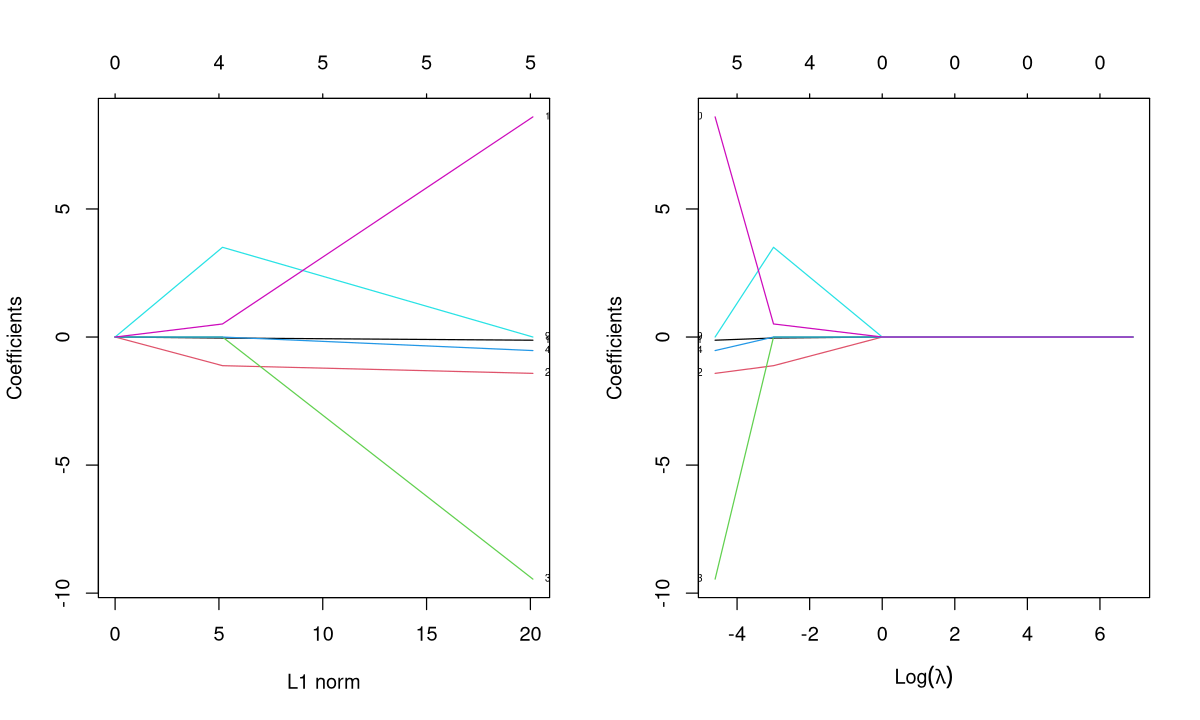

In [27]:
par(mfrow = c(1, 2))
plot(lasso.mod, xvar = "norm", xlab = "L1 norm", label = TRUE)
plot(lasso.mod, xvar = "lambda", sign.lambda = 1, label = TRUE)
par(mfrow = c(1, 1))

Comparé au graphe *Log Lambda* de Ridge, on remarque que les coefficients du Lasso **atteignent 0 beaucoup plus rapidement** : pour λ ≥ 1, **aucune** variable n'est gardée (`Df = 0`, seul l'intercept = moyenne de log10(y) ≈ 2.02) ; pour λ = 0.05, 4 variables ; pour λ = 0.01, 5 variables. C'est pourquoi le Lasso est une méthode intéressante pour **sélectionner les variables explicatives les plus intéressantes**.

> Un *warning* « suppression des ex-aequos de 'x' » (*collapsing to unique 'x' values*) peut apparaître avec `xvar = "norm"` : plusieurs λ donnent la même norme (ici 0). Il est sans conséquence.

### 6.7.3 Elastic Net


Call:  glmnet(x = x, y = log10(y), family = "gaussian", alpha = 0.5,      lambda = c(1000, 100, 10, 1, 0.05, 0.01)) 

  Df  %Dev Lambda
1  0  0.00  1e+03
2  0  0.00  1e+02
3  0  0.00  1e+01
4  0  0.00  1e+00
5  5 33.62  5e-02
6  7 37.97  1e-02


Warning message in regularize.values(x, y, ties, missing(ties), na.rm = na.rm):
“collapsing to unique 'x' values”


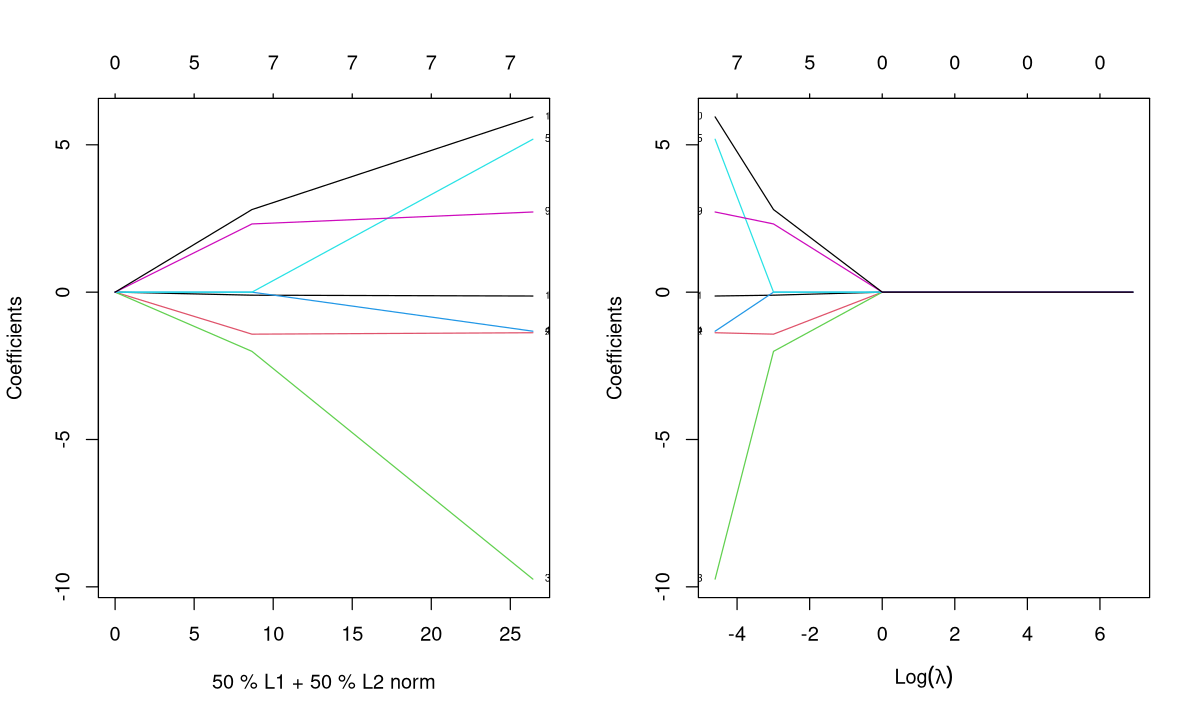

In [28]:
# alpha = 0.5 -> 50 % L1, 50 % L2
elastic.mod <- glmnet(x, log10(y), alpha = 0.5,
                      lambda = c(1000, 100, 10, 1, 0.05, 0.01), family = "gaussian")
print(elastic.mod)

par(mfrow = c(1, 2))
plot(elastic.mod, xvar = "norm", xlab = "50 % L1 + 50 % L2 norm", label = TRUE)
plot(elastic.mod, xvar = "lambda", sign.lambda = 1, label = TRUE)
par(mfrow = c(1, 1))

Comme le dit la résolution : avec α, on peut se placer plus près de Ridge ou du Lasso ; **le nom de l'axe x est faux** : c'est un **mélange de 50 % de norme L1 et 50 % de norme L2**.

### Exercice 6.8 : laisser glmnet choisir la séquence de λ

La séquence `c(1000, 100, 10, 1, 0.05, 0.01)` est très grossière (pour le Lasso, tout se passe entre 1 et 0.01 !).

1. Ajuste un Lasso sur `x` et `log10(y)` **sans** donner `lambda`. Combien de λ sont utilisés ? Quel est le plus grand ?
2. Trace le chemin `xvar = "lambda", sign.lambda = 1` avec les étiquettes.
3. À l'aide de `mod$df`, trouve le plus grand λ pour lequel **3 variables** sont dans le modèle, et affiche leurs noms.

In [29]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
lasso.auto <- glmnet(x, log10(y), alpha = 1)
length(lasso.auto$lambda); max(lasso.auto$lambda)
plot(lasso.auto, xvar = "lambda", sign.lambda = 1, label = TRUE)
l3 <- lasso.auto$lambda[min(which(lasso.auto$df == 3))]
l3
b <- coef(lasso.auto, s = l3)
rownames(b)[as.numeric(b) != 0]
```

Le plus grand λ calculé par glmnet ($\lambda_{max}$) est la plus petite valeur pour laquelle **tous** les coefficients sont nuls ; glmnet descend ensuite sur une échelle logarithmique jusqu'à $\lambda_{max}/10\,000$ environ (si n > p). La séquence automatique décrit le chemin beaucoup plus finement que la grille de la résolution.

</details>

## 6.8 Lasso sur le spectre complet

Jusqu'ici, on s'est limité aux 10 features les plus corrélées (choix arbitraire). L'avantage du Lasso est qu'il peut travailler directement sur **les 1060 points spectraux**, même si p > n (ici p = 1060 > n = 178), situation où l'OLS est impossible : il fait lui-même la sélection.

[1]  178 1060

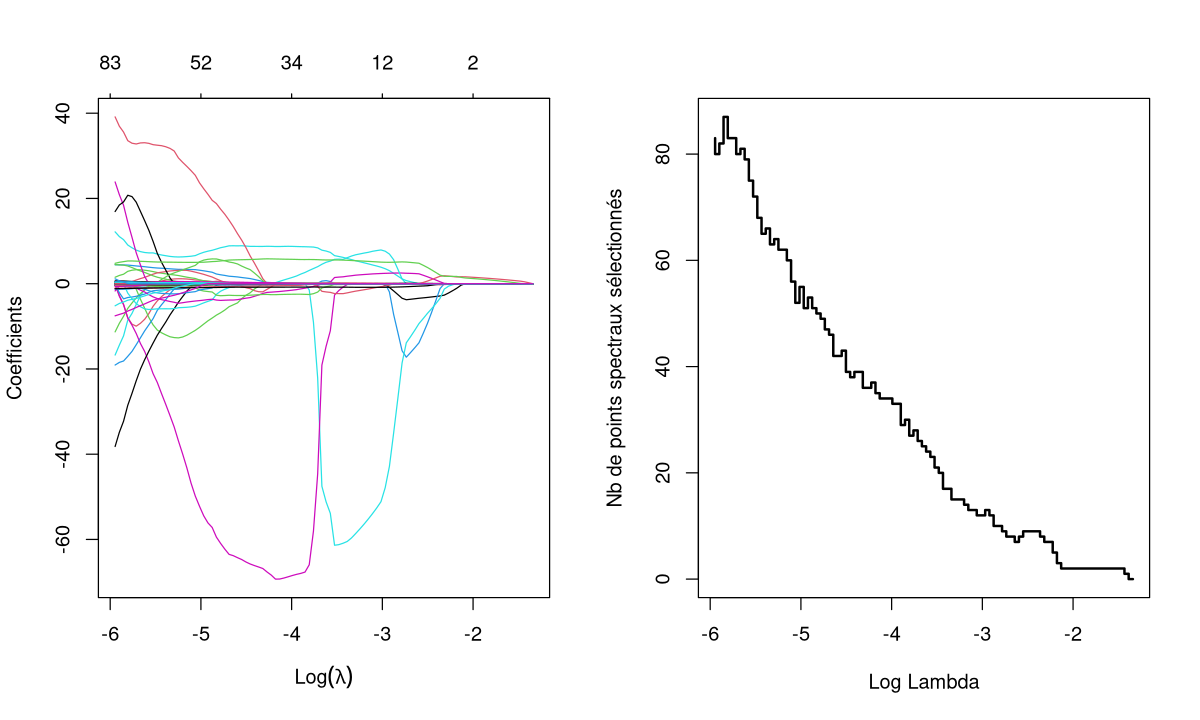

In [30]:
X_all <- as.matrix(lactoferrin[, 2:1061])     # tout le spectre
dim(X_all)

lasso.full <- glmnet(X_all, log10(y), alpha = 1)   # séquence de λ automatique
par(mfrow = c(1, 2))
plot(lasso.full, xvar = "lambda", sign.lambda = 1)
plot(log(lasso.full$lambda), lasso.full$df, type = "s", lwd = 2,
     xlab = "Log Lambda", ylab = "Nb de points spectraux sélectionnés")
par(mfrow = c(1, 1))

[1] "V161" "V162" "V210" "V458" "V553" "V591" "V592" "V607" "V609" "V631"
[11] "V632" "V636" "V662" "V680" "V713"

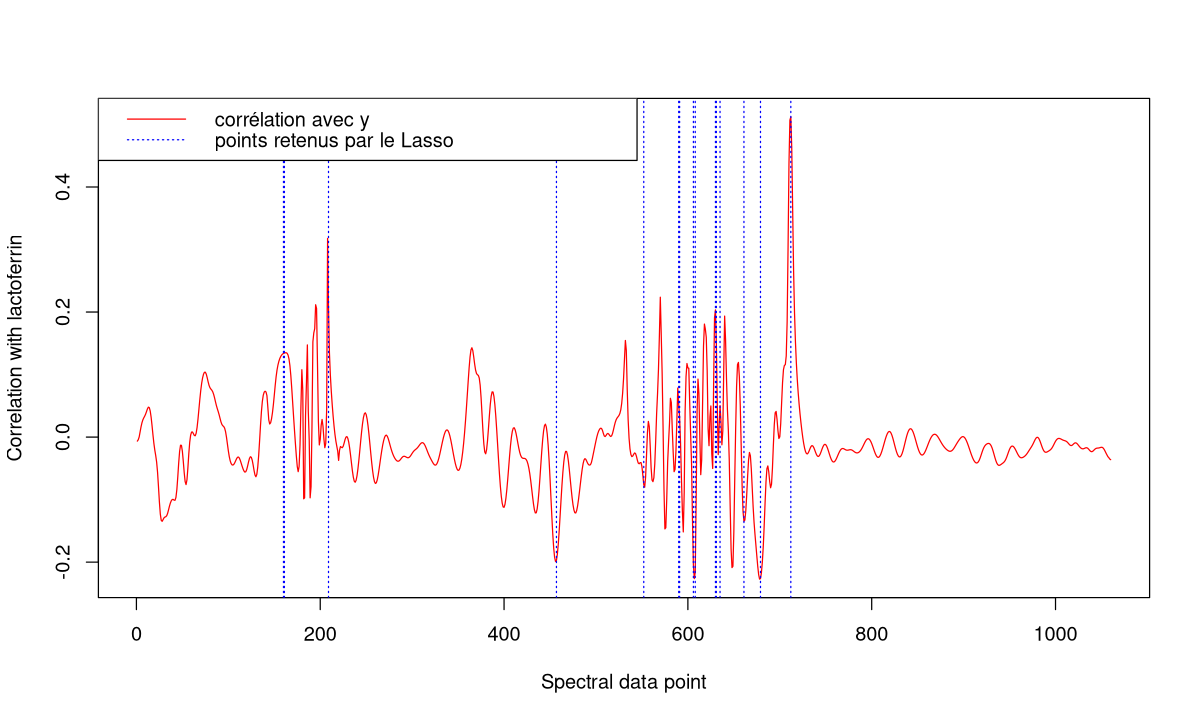

In [31]:
# Quels points spectraux sont retenus pour un λ donné ? (ex. λ donnant ~ 15 variables)
s_15 <- lasso.full$lambda[min(which(lasso.full$df >= 15))]
b_15 <- coef(lasso.full, s = s_15)[-1, 1]          # sans l'intercept
sel_15 <- which(b_15 != 0)
names(sel_15)

# Position des points sélectionnés sur le spectre de corrélation
plot(correlation, type = "l", col = "red", xlab = "Spectral data point",
     ylab = "Correlation with lactoferrin")
abline(v = sel_15, col = "blue", lty = 3)
legend("topleft", c("corrélation avec y", "points retenus par le Lasso"),
       col = c("red", "blue"), lty = c(1, 3))

Le Lasso ne retient pas forcément les points les **plus corrélés** individuellement : il cherche une **combinaison** de points complémentaires, et parmi des points adjacents très corrélés entre eux, il n'en garde souvent qu'**un** (cf. mise en garde sur l'interprétation).

### Exercice 6.9 : Ridge sur le spectre complet

Ajuste un Ridge sur le spectre complet (`X_all`, `log10(y)`). Compare son graphe *Log Lambda* et la colonne `Df` de `print()` avec ceux du Lasso. Explique la différence.

In [32]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
ridge.full <- glmnet(X_all, log10(y), alpha = 0)
plot(ridge.full, xvar = "lambda", sign.lambda = 1)
head(print(ridge.full))
```

Pour Ridge, `Df` vaut **1060 pour tous les λ** : aucun coefficient n'est exactement nul, toutes les variables restent dans le modèle avec de petits coefficients. Le graphe montre un « faisceau » de 1060 courbes qui convergent doucement vers 0. Ridge ne fait **pas** de sélection de variables, le Lasso oui.

</details>

## 6.9 Choisir λ : grille sur un jeu de validation

Le syllabus : « *le bon réglage de ce paramètre se fait par essais successifs. La grille (grid) consiste à tester différentes valeurs d'un paramètre, ici λ, sur un jeu de validation.* »

Démarche :

1. séparer les données en un jeu de **calibration** (*training*) et un jeu de **validation** **indépendant** ;
2. pour chaque λ de la grille, ajuster le modèle sur la calibration ;
3. calculer l'erreur de prédiction sur la validation, par exemple le **RMSEP** (*root mean square error of prediction*) $= \sqrt{\frac{1}{n_{val}}\sum (y_i - \hat y_i)^2}$ ;
4. retenir le λ qui **minimise l'erreur de validation**.

> Avec seulement 178 échantillons, le résultat dépend du tirage aléatoire de la séparation : la validation sera traitée en détail au **module 2**.

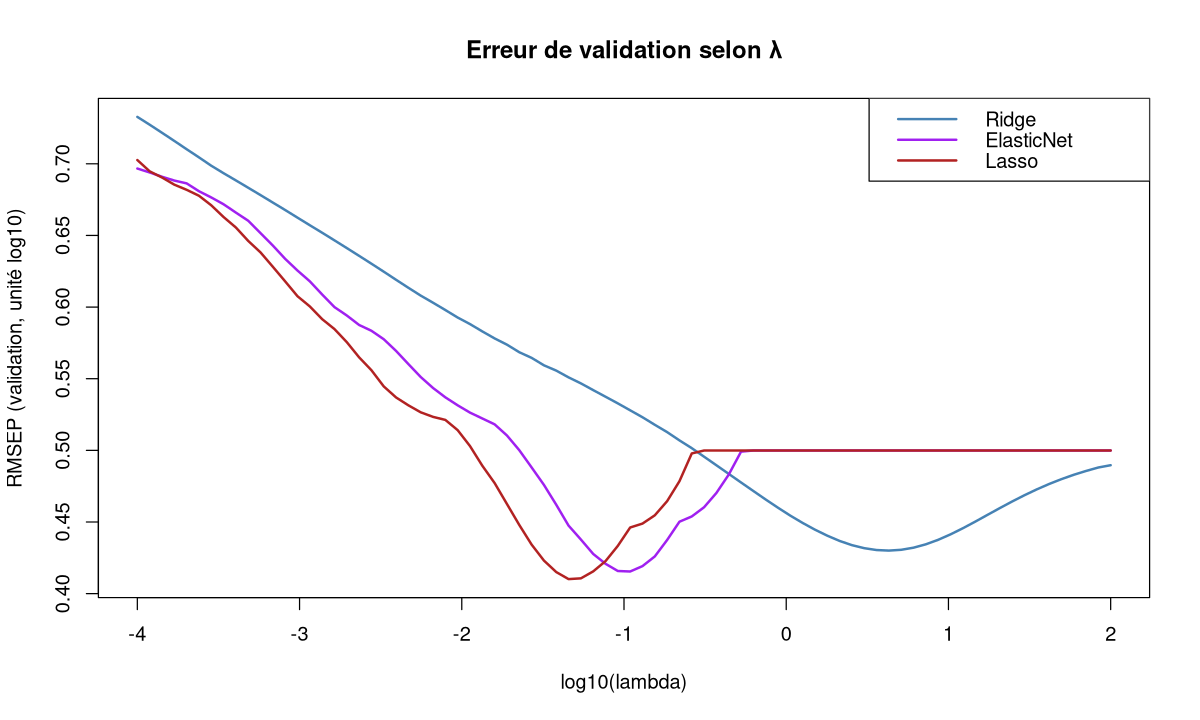

In [33]:
set.seed(123)                                    # rend le tirage reproductible
n     <- nrow(X_all)
i_cal <- sample(1:n, size = round(0.75 * n))     # 75 % calibration
i_val <- setdiff(1:n, i_cal)                     # 25 % validation

ly <- log10(y)
grid <- 10^seq(2, -4, length.out = 80)           # grille de λ (décroissante), de 100 à 0.0001

rmsep <- function(obs, pred) sqrt(mean((obs - pred)^2))

res_grid <- sapply(c(Ridge = 0, ElasticNet = 0.5, Lasso = 1), function(a) {
  m    <- glmnet(X_all[i_cal, ], ly[i_cal], alpha = a, lambda = grid)
  pred <- predict(m, newx = X_all[i_val, ], s = grid)      # une colonne par λ
  apply(pred, 2, function(p) rmsep(ly[i_val], p))
})

matplot(log10(grid), res_grid, type = "l", lty = 1, lwd = 2, col = c("steelblue", "purple", "firebrick"),
        xlab = "log10(lambda)", ylab = "RMSEP (validation, unité log10)", main = "Erreur de validation selon λ")
legend("topright", colnames(res_grid), col = c("steelblue", "purple", "firebrick"), lty = 1, lwd = 2)

In [34]:
# Meilleur λ pour chaque méthode
best <- apply(res_grid, 2, which.min)
data.frame(methode   = colnames(res_grid),
           lambda    = signif(grid[best], 3),
           RMSEP_val = round(res_grid[cbind(best, 1:3)], 4))

# Référence : OLS sur les 10 features les plus corrélées, mêmes jeux cal/val
ols10 <- lm(ly[i_cal] ~ x[i_cal, ])
pred_ols10 <- cbind(1, x[i_val, ]) %*% coef(ols10)
c(RMSEP_OLS_10_features = round(rmsep(ly[i_val], pred_ols10), 4))

methode,lambda,RMSEP_val
<chr>,<dbl>,<dbl>
Ridge,4.2900,0.4300
ElasticNet,0.1090,0.4155
Lasso,0.0455,0.4101


RMSEP_OLS_10_features 
               0.4614

On lit la courbe de **droite à gauche** (λ décroissant) : à grand λ (à droite), le modèle est trop pénalisé (**sous-ajustement** ; pour le Lasso et l'Elastic Net, le plateau correspond au modèle réduit à l'intercept) ; quand λ diminue, l'erreur diminue jusqu'à un **minimum** ; pour les très petits λ (à gauche), le modèle utilise trop librement les 1060 variables (**surajustement**) et l'erreur de validation remonte. Le λ optimal est au **creux** de la courbe. Les trois méthodes pénalisées sur le spectre complet font mieux en validation que l'OLS sur les 10 features les plus corrélées.

> **Complément : `cv.glmnet()`, la validation croisée automatique**
> Plutôt qu'une seule séparation calibration/validation, `cv.glmnet()` découpe les données en `nfolds` (10 par défaut) blocs : chaque bloc sert à tour de rôle de validation. On obtient une courbe d'erreur moyenne ± erreur standard et deux λ remarquables :
> - `lambda.min` : λ qui minimise l'erreur moyenne de validation croisée ;
> - `lambda.1se` : le plus grand λ dont l'erreur reste à moins d'une erreur standard du minimum (modèle plus **parcimonieux**, souvent préféré).
> La validation croisée sera détaillée au **module 2**.

lambda.min lambda.1se 
0.04070916 0.07114041

n_var_min n_var_1se 
       15         8

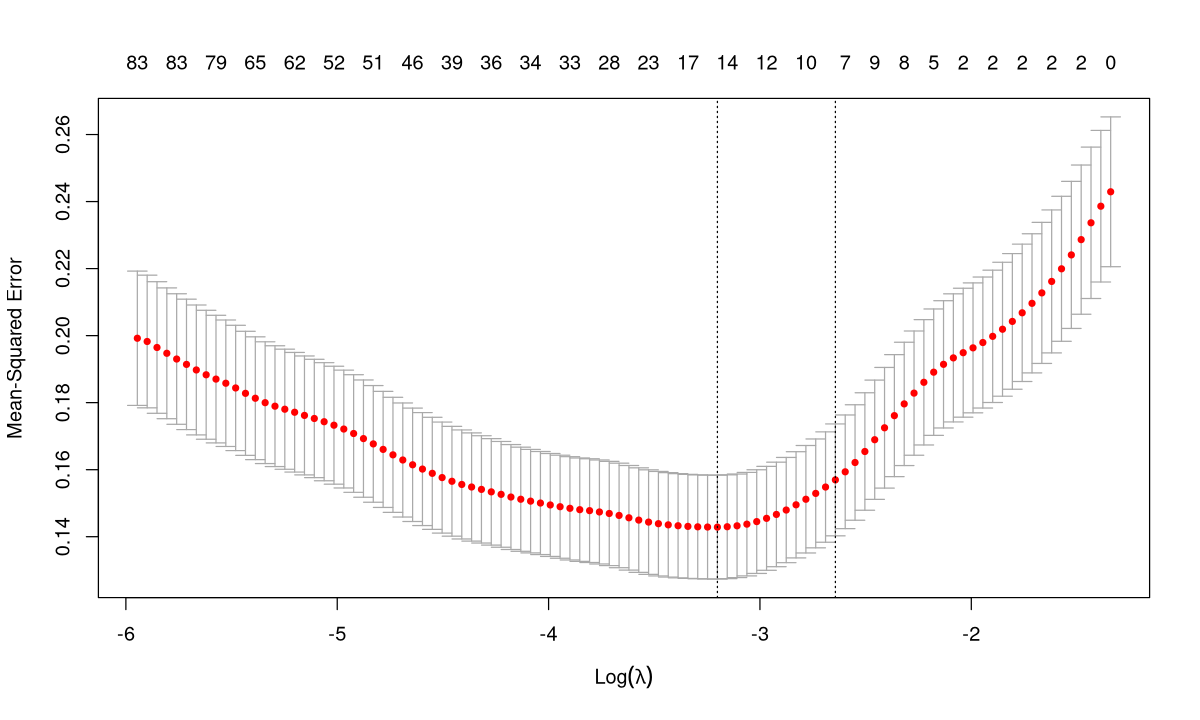

In [35]:
set.seed(123)
cv.lasso <- cv.glmnet(X_all, ly, alpha = 1, nfolds = 10)
plot(cv.lasso, sign.lambda = 1)      # en haut : nb de variables ; lignes pointillées : lambda.min et lambda.1se
c(lambda.min = cv.lasso$lambda.min, lambda.1se = cv.lasso$lambda.1se)

# Nombre de points spectraux retenus pour chacun
c(n_var_min = sum(coef(cv.lasso, s = "lambda.min")[-1] != 0),
  n_var_1se = sum(coef(cv.lasso, s = "lambda.1se")[-1] != 0))

### Exercice 6.10 : prédire avec le λ choisi

1. Avec `cv.lasso`, prédis la teneur en lactoferrine **en mg/L** (attention à la transformation log10 !) des 5 premiers échantillons, avec `s = "lambda.1se"`.
2. Compare aux valeurs observées.

In [36]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
pred_log <- predict(cv.lasso, newx = X_all[1:5, ], s = "lambda.1se")
pred_mgL <- 10^pred_log                 # rétro-transformation : 10^(log10(y)) = y
cbind(observe = y[1:5], predit = round(as.numeric(pred_mgL), 1))
```

Les prédictions restent assez éloignées des observations : avec un RMSEP ≈ 0.41 en log10 (un facteur ≈ 2.6 en mg/L !), la lactoferrine, protéine mineure, reste difficile à prédire à partir du spectre.

Le modèle a été ajusté sur `log10(y)` : ses prédictions sont en unités log10. Il faut appliquer la **transformation inverse** `10^` pour revenir en mg/L. `predict()` sur un objet `cv.glmnet` accepte directement `s = "lambda.min"` ou `s = "lambda.1se"`.

</details>

### Exercice 6.11 : choisir α aussi

Avec la même séparation `i_cal` / `i_val`, teste α ∈ {0, 0.25, 0.5, 0.75, 1} et, pour chacun, le meilleur λ de `grid`. Quel couple (α, λ) minimise le RMSEP de validation ?

In [37]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
alphas <- c(0, 0.25, 0.5, 0.75, 1)
res_a <- t(sapply(alphas, function(a) {
  m    <- glmnet(X_all[i_cal, ], ly[i_cal], alpha = a, lambda = grid)
  e    <- apply(predict(m, newx = X_all[i_val, ], s = grid), 2, function(p) rmsep(ly[i_val], p))
  c(alpha = a, lambda = grid[which.min(e)], RMSEP = min(e))
}))
res_a
res_a[which.min(res_a[, "RMSEP"]), ]
```

On fait une **grille à deux dimensions** (α × λ). Le couple retenu est celui de plus faible RMSEP. Attention : comme on choisit le meilleur parmi beaucoup de modèles sur le même jeu de validation, ce RMSEP est un peu optimiste. Idéalement, on garde un troisième jeu (*test*) pour l'évaluation finale (module 2).

</details>

## 6.10 Bilan : la sélection de variables

La slide de synthèse « *Feature selection – Variable selection* » :

- **régressions pénalisées** :
  - **Lasso** ;
  - **Elastic-Net** ;
- **autres méthodes** (cf. partie 4 et le cours « *Analyse Multivariée 1 : Exploration de données* ») :
  - **Stepwise** ;
  - **Backward** ;
  - **Forward**.

Ridge n'est pas dans la liste : il **rétrécit** mais ne **sélectionne** pas. Quand les variables sont très nombreuses et fortement corrélées (spectres), d'autres méthodes réduisant la dimension de X (PCR, PLS) seront vues au **module 2**.

### Question de compréhension 6.12 (QCM)

1. Dans `glmnet`, quelle valeur de `alpha` donne une régression Ridge ? (a) 1 (b) 0 (c) 0.5
2. `print(mod)` affiche `Df = 0` pour un λ donné. Cela signifie : (a) 0 degré de liberté résiduel (b) aucun coefficient non nul hormis l'intercept (c) une erreur
3. Pourquoi standardiser les x avant une régression pénalisée ? (a) pour que les résidus soient normaux (b) pour donner la même pénalité à toutes les variables (c) pour accélérer `lm()`
4. Quand λ → ∞, la prédiction d'un modèle Lasso tend vers : (a) 0 (b) la moyenne de y (c) la prédiction OLS

<details>
<summary><b>Voir la solution</b></summary>

1. **(b)** α = 0 → Ridge ; α = 1 → Lasso ; 0.5 → Elastic Net « au milieu ».
2. **(b)** `Df` = nombre de coefficients non nuls (l'intercept n'est pas compté).
3. **(b)** La pénalité porte sur la taille des coefficients, qui dépend de l'échelle des variables.
4. **(b)** Tous les coefficients sont nuls, il ne reste que l'intercept (non pénalisé) = $\bar y$.

</details>

## Récapitulatif

**Points clés**

- Les régressions pénalisées ajoutent à l'OLS une **pénalité sur la taille des coefficients**, contrôlée par **λ** : λ = 0 → OLS ; λ ↑ → coefficients rétrécis vers 0 ; λ trop grand → sous-ajustement.
- **Ridge (L2, Σβ²)** : rétrécissement progressif, **jamais de 0 exact**, stable face à la colinéarité (X'X + λI toujours inversible), partage l'effet entre variables corrélées → idéal pour **beaucoup de petits effets**.
- **Lasso (L1, Σ|β|)** : coefficients **exactement nuls** → **sélection automatique** ; garde une seule variable parmi des variables corrélées (prudence d'interprétation) ; risque de sous-ajustement → idéal pour **quelques effets modérés/forts**.
- **Elastic Net** : L1 + L2 ; dans glmnet, **α** règle le mélange (0 = Ridge, 1 = Lasso).
- **Toujours standardiser** les x (glmnet le fait par défaut).
- **λ se choisit par une grille testée sur un jeu de validation** (ou par validation croisée `cv.glmnet`) ; l'échelle de λ dépend de l'implémentation.

**Fonctions R vues**

| Fonction | Rôle |
|---|---|
| `glmnet(x, y, alpha, lambda, family, standardize)` | ajuste Ridge / Lasso / Elastic Net sur un chemin de λ |
| `print(mod)` | tableau Df / %Dev / Lambda |
| `coef(mod, s = )` | coefficients pour un λ |
| `predict(mod, newx = , s = )` | prédictions pour un λ |
| `plot(mod, xvar = "norm" / "lambda" / "dev", label = TRUE)` | chemins de coefficients |
| `mod$lambda`, `mod$beta`, `mod$a0`, `mod$df`, `mod$dev.ratio` | contenu de l'objet glmnet |
| `cv.glmnet(x, y, alpha, nfolds)`, `$lambda.min`, `$lambda.1se` | choix de λ par validation croisée |
| `solve(crossprod(X) + lambda * diag(p), crossprod(X, y))` | Ridge analytique (maison) |
| `set.seed()`, `sample()`, `setdiff()` | séparation calibration / validation |

**Suite** : la partie 7 est le **TP guidé du Homework 1** (acides gras saturés), qui mobilise tout le module, y compris le Lasso sur le spectre complet.